#Peramalan Beban Listrik Jangka Pendek (Short-Term Load Forecasting) Menggunakan Pendekatan Machine Learning vs Deep Learning

tujuan dari proyek ini adalah untuk memprediksi kebutuhan listrik dalam satuan MW per jam untuk Republik Dominika yang akan digunakan untuk efisiensi pembangkitan energi.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn
import statsmodels.api as sm
import xgboost as xgb
from statsmodels.tsa.stattools import adfuller
import math

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_percentage_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping
import tensorflow as tf

from sklearn.linear_model import LinearRegression

In [ ]:
df = pd.read_csv("/content/datos_modelo.csv")

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35039 entries, 0 to 35038
Data columns (total 33 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   timestamp               35039 non-null  object 
 1   active_power_mw         35039 non-null  float64
 2   apparent_temperature_c  35039 non-null  float64
 3   cloud_cover_percent     35039 non-null  float64
 4   month                   35039 non-null  int64  
 5   hour                    35039 non-null  int64  
 6   is_holiday              35039 non-null  int64  
 7   is_weekend              35039 non-null  int64  
 8   is_school_vacation      35039 non-null  int64  
 9   active_power_lag_1h     35039 non-null  float64
 10  active_power_lag_2h     35039 non-null  float64
 11  active_power_lag_3h     35039 non-null  float64
 12  active_power_lag_4h     35039 non-null  float64
 13  active_power_lag_5h     35039 non-null  float64
 14  active_power_lag_6h     35039 non-null

#EDA

In [ ]:
df.head(5)

,timestamp,active_power_mw,apparent_temperature_c,cloud_cover_percent,month,hour,is_holiday,is_weekend,is_school_vacation,active_power_lag_1h,...,active_power_lag_15h,active_power_lag_16h,active_power_lag_17h,active_power_lag_18h,active_power_lag_19h,active_power_lag_20h,active_power_lag_21h,active_power_lag_22h,active_power_lag_23h,active_power_lag_24h
0,2/1/21 1:00,1508.726498,22.100000,21.766667,1,1,0,1,0,1569.519607,...,1482.275419,1466.580228,1467.914176,1523.332766,1514.568961,1540.221065,1575.752549,1629.903638,1674.169500,1703.356546
1,2/1/21 2:00,1474.224972,21.803333,26.833333,1,2,0,1,0,1508.726498,...,1492.911710,1482.275419,1466.580228,1467.914176,1523.332766,1514.568961,1540.221065,1575.752549,1629.903638,1674.169500
2,2/1/21 3:00,1448.436605,21.633333,22.300000,1,3,0,1,0,1474.224972,...,1481.049047,1492.911710,1482.275419,1466.580228,1467.914176,1523.332766,1514.568961,1540.221065,1575.752549,1629.903638
3,2/1/21 4:00,1426.507838,21.223333,25.766667,1,4,0,1,0,1448.436605,...,1484.485208,1481.049047,1492.911710,1482.275419,1466.580228,1467.914176,1523.332766,1514.568961,1540.221065,1575.752549
4,2/1/21 5:00,1419.126334,21.003333,17.533333,1,5,0,1,0,1426.507838,...,1466.621504,1484.485208,1481.049047,1492.911710,1482.275419,1466.580228,1467.914176,1523.332766,1514.568961,1540.221065


In [ ]:
df.shape

(35039, 33)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35039 entries, 0 to 35038
Data columns (total 33 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   timestamp               35039 non-null  object 
 1   active_power_mw         35039 non-null  float64
 2   apparent_temperature_c  35039 non-null  float64
 3   cloud_cover_percent     35039 non-null  float64
 4   month                   35039 non-null  int64  
 5   hour                    35039 non-null  int64  
 6   is_holiday              35039 non-null  int64  
 7   is_weekend              35039 non-null  int64  
 8   is_school_vacation      35039 non-null  int64  
 9   active_power_lag_1h     35039 non-null  float64
 10  active_power_lag_2h     35039 non-null  float64
 11  active_power_lag_3h     35039 non-null  float64
 12  active_power_lag_4h     35039 non-null  float64
 13  active_power_lag_5h     35039 non-null  float64
 14  active_power_lag_6h     35039 non-null

##Distribusi kolom lain

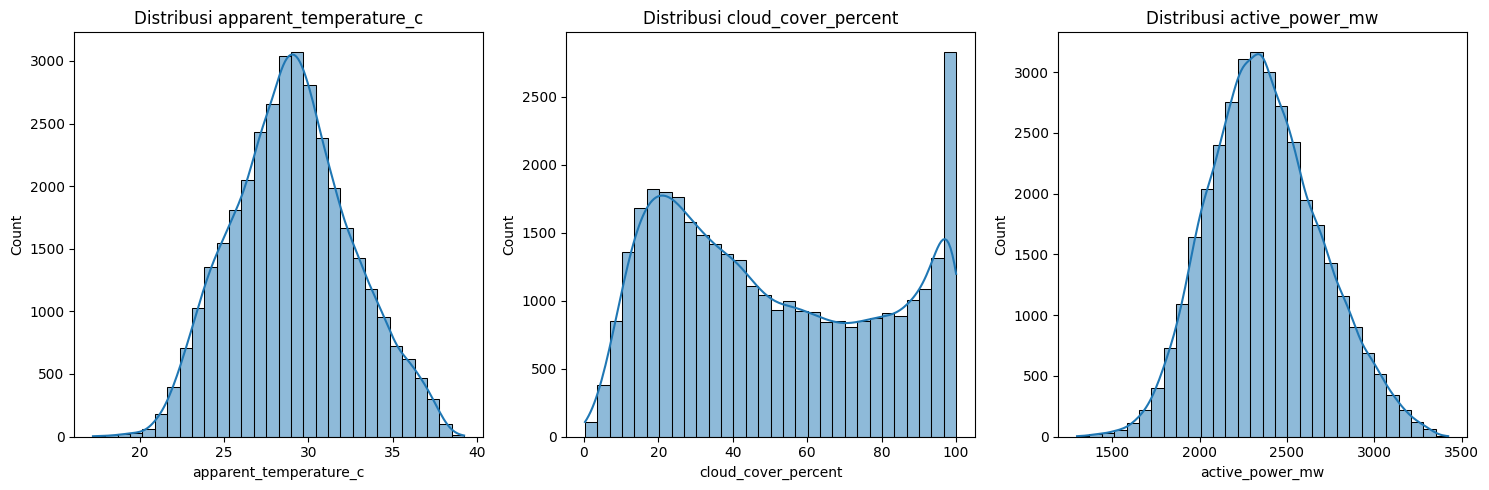

is_holiday
0    33911
1     1128
Name: count, dtype: int64


In [ ]:
cols_to_check = ['apparent_temperature_c', 'cloud_cover_percent', 'active_power_mw']

plt.figure(figsize=(15, 5))
for i, col in enumerate(cols_to_check):
    plt.subplot(1, 3, i+1)
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(f'Distribusi {col}')
plt.tight_layout()
plt.show()

print(df['is_holiday'].value_counts())

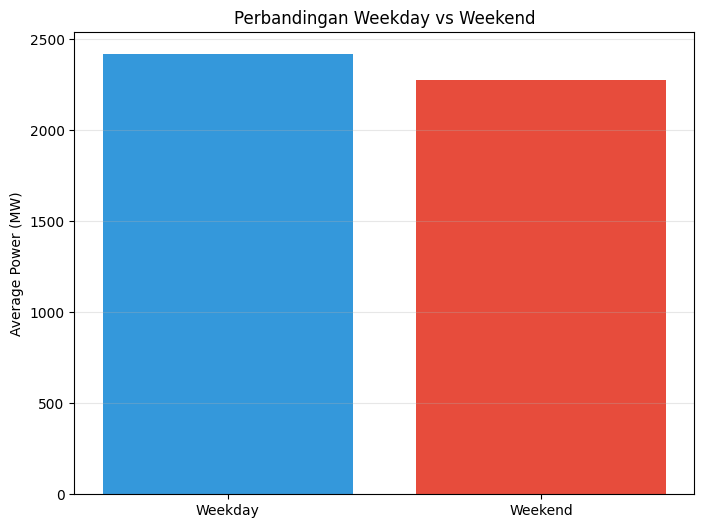

In [ ]:
plt.figure(figsize=(8, 6)) # Create a new figure with a larger size
weekend_comparison = df.groupby('is_weekend')['active_power_mw'].mean()
labels = ['Weekday', 'Weekend']
plt.bar(labels, weekend_comparison.values, color=['#3498db', '#e74c3c'])
plt.ylabel('Average Power (MW)')
plt.title('Perbandingan Weekday vs Weekend')
plt.grid(True, alpha=0.3, axis='y')

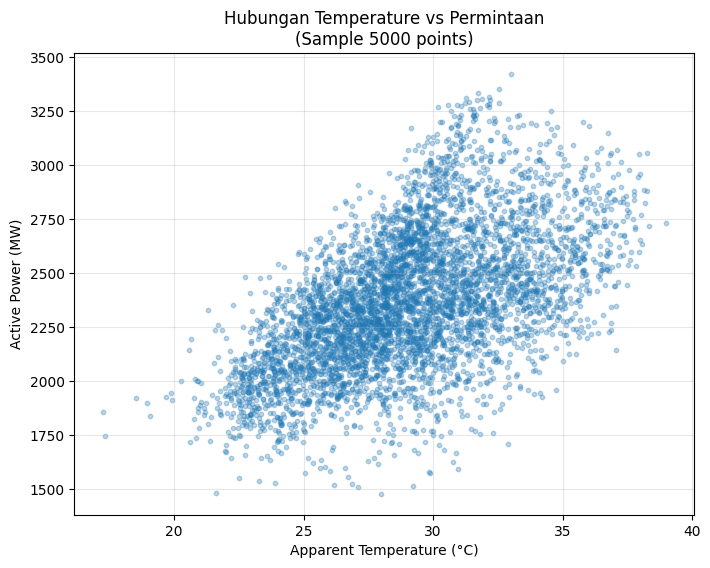

In [ ]:
plt.figure(figsize=(8, 6)) # Create a new figure with a larger size
# Sample untuk scatter plot (5000 points)
sample_idx = np.random.choice(len(df), min(5000, len(df)), replace=False)
plt.scatter(df.iloc[sample_idx]['apparent_temperature_c'],
            df.iloc[sample_idx]['active_power_mw'],
            alpha=0.3, s=10)
plt.xlabel('Apparent Temperature (°C)')
plt.ylabel('Active Power (MW)')
plt.title('Hubungan Temperature vs Permintaan\n(Sample 5000 points)')
plt.grid(True, alpha=0.3)

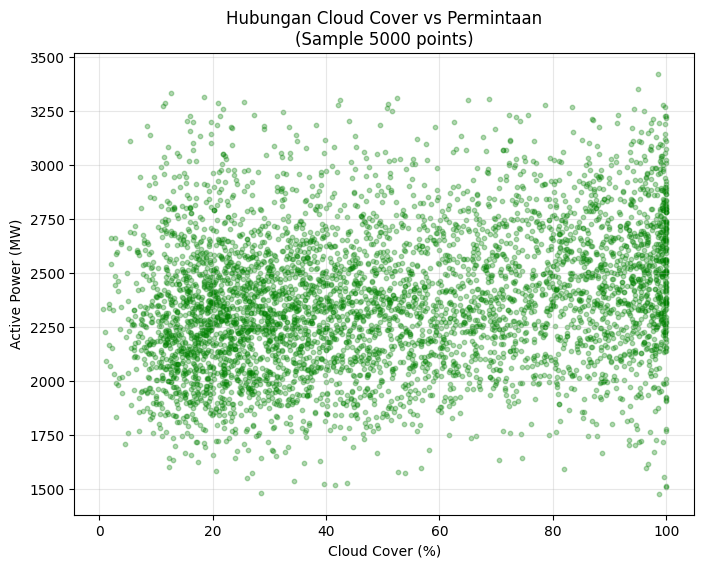

In [ ]:
plt.figure(figsize=(8, 6)) # Create a new figure with a larger size
plt.scatter(df.iloc[sample_idx]['cloud_cover_percent'],
            df.iloc[sample_idx]['active_power_mw'],
            alpha=0.3, s=10, color='green')
plt.xlabel('Cloud Cover (%)')
plt.ylabel('Active Power (MW)')
plt.title('Hubungan Cloud Cover vs Permintaan\n(Sample 5000 points)')
plt.grid(True, alpha=0.3)

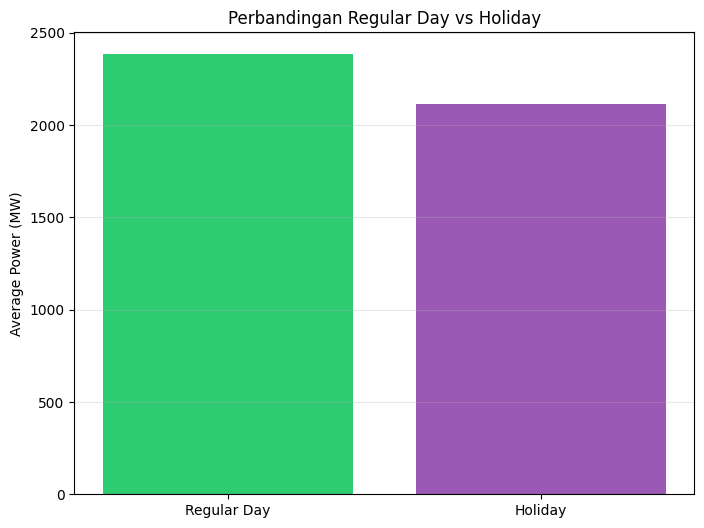

In [ ]:
plt.figure(figsize=(8, 6)) # Create a new figure with a larger size
holiday_comparison = df.groupby('is_holiday')['active_power_mw'].mean()
labels = ['Regular Day', 'Holiday']
plt.bar(labels, holiday_comparison.values, color=['#2ecc71', '#9b59b6'])
plt.ylabel('Average Power (MW)')
plt.title('Perbandingan Regular Day vs Holiday')
plt.grid(True, alpha=0.3, axis='y')
plt.show()

In [ ]:
df.head()

,timestamp,active_power_mw,apparent_temperature_c,cloud_cover_percent,month,hour,is_holiday,is_weekend,is_school_vacation,active_power_lag_1h,...,active_power_lag_15h,active_power_lag_16h,active_power_lag_17h,active_power_lag_18h,active_power_lag_19h,active_power_lag_20h,active_power_lag_21h,active_power_lag_22h,active_power_lag_23h,active_power_lag_24h
0,2/1/21 1:00,1508.726498,22.100000,21.766667,1,1,0,1,0,1569.519607,...,1482.275419,1466.580228,1467.914176,1523.332766,1514.568961,1540.221065,1575.752549,1629.903638,1674.169500,1703.356546
1,2/1/21 2:00,1474.224972,21.803333,26.833333,1,2,0,1,0,1508.726498,...,1492.911710,1482.275419,1466.580228,1467.914176,1523.332766,1514.568961,1540.221065,1575.752549,1629.903638,1674.169500
2,2/1/21 3:00,1448.436605,21.633333,22.300000,1,3,0,1,0,1474.224972,...,1481.049047,1492.911710,1482.275419,1466.580228,1467.914176,1523.332766,1514.568961,1540.221065,1575.752549,1629.903638
3,2/1/21 4:00,1426.507838,21.223333,25.766667,1,4,0,1,0,1448.436605,...,1484.485208,1481.049047,1492.911710,1482.275419,1466.580228,1467.914176,1523.332766,1514.568961,1540.221065,1575.752549
4,2/1/21 5:00,1419.126334,21.003333,17.533333,1,5,0,1,0,1426.507838,...,1466.621504,1484.485208,1481.049047,1492.911710,1482.275419,1466.580228,1467.914176,1523.332766,1514.568961,1540.221065


##Correlation heatmap

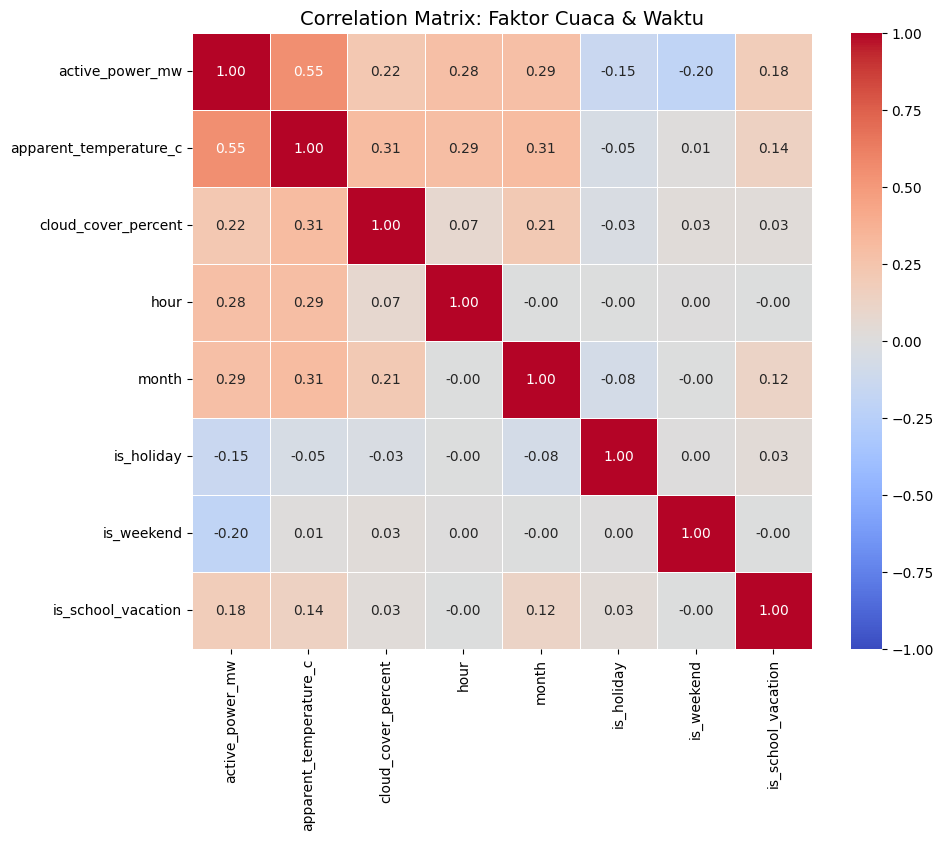

In [ ]:
cols_to_corr = [
    'active_power_mw', 'apparent_temperature_c', 'cloud_cover_percent',
    'hour', 'month', 'is_holiday', 'is_weekend', 'is_school_vacation'
]

corr_matrix = df[cols_to_corr].corr(method='pearson')

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    linewidths=0.5,
    vmin=-1, vmax=1
)
plt.title('Correlation Matrix: Faktor Cuaca & Waktu', fontsize=14)
plt.show()

/tmp/ipython-input-263903489.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(x=lag_correlations.values, y=lag_correlations.index, palette='Blues_r')


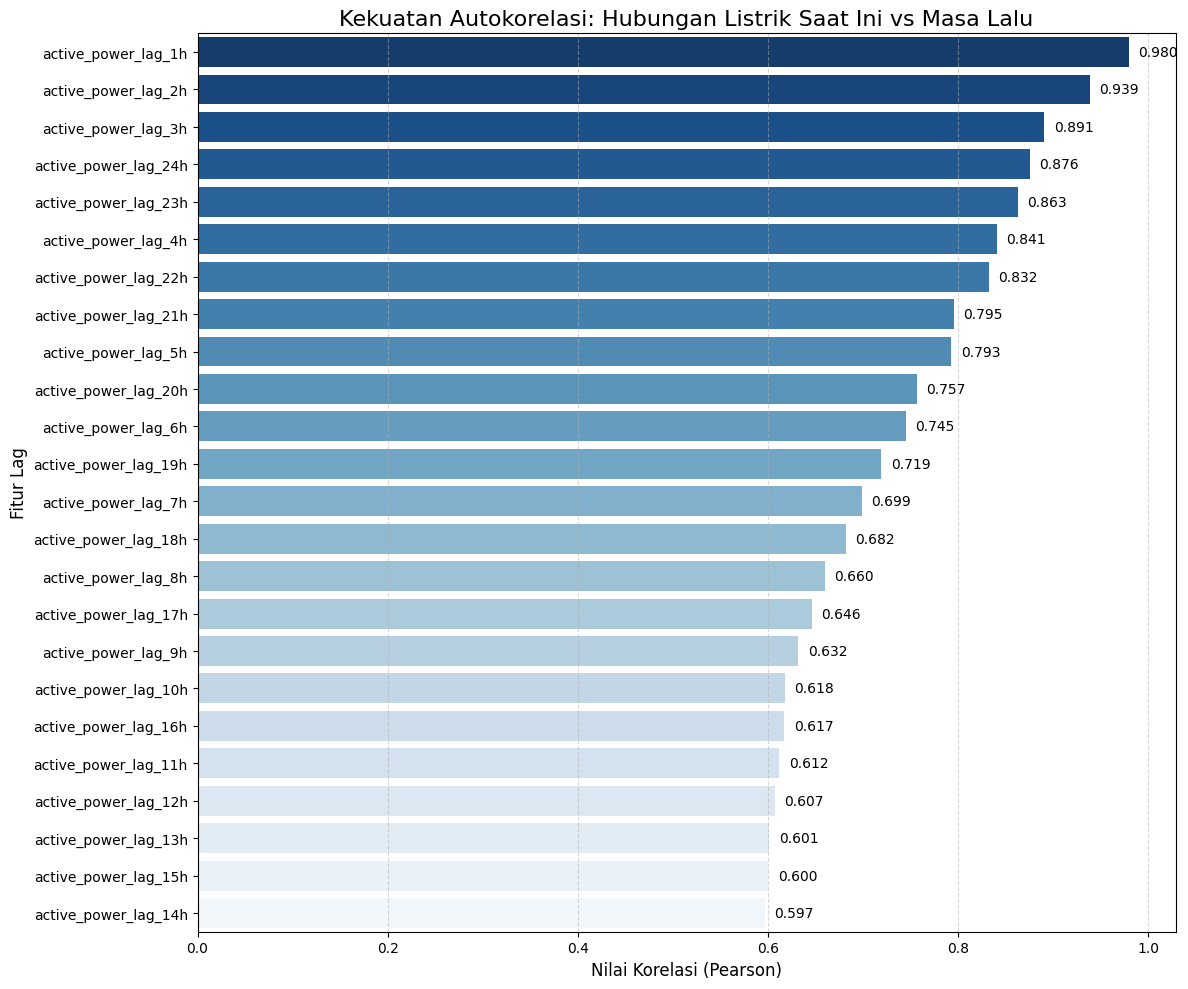

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

target = 'active_power_mw'
lag_cols = [col for col in df.columns if 'lag' in col]
lag_correlations = df[lag_cols + [target]].corr()[target].drop(target)
lag_correlations = lag_correlations.sort_values(ascending=False)
plt.figure(figsize=(12, 10))
barplot = sns.barplot(x=lag_correlations.values, y=lag_correlations.index, palette='Blues_r')
plt.title('Kekuatan Autokorelasi: Hubungan Listrik Saat Ini vs Masa Lalu', fontsize=16)
plt.xlabel('Nilai Korelasi (Pearson)', fontsize=12)
plt.ylabel('Fitur Lag', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)

for i, v in enumerate(lag_correlations.values):
    plt.text(v + 0.01, i, f'{v:.3f}', va='center', fontsize=10)

plt.tight_layout()
plt.show()

##Gambaran besar kebutuhan listrik

In [ ]:
min_power = df['active_power_mw'].min()
max_power = df['active_power_mw'].max()

print(f"Minimum active power: {min_power} MW")
print(f"Maximum active power: {max_power} MW")

Minimum active power: 1298.711986 MW
Maximum active power: 3422.594406 MW


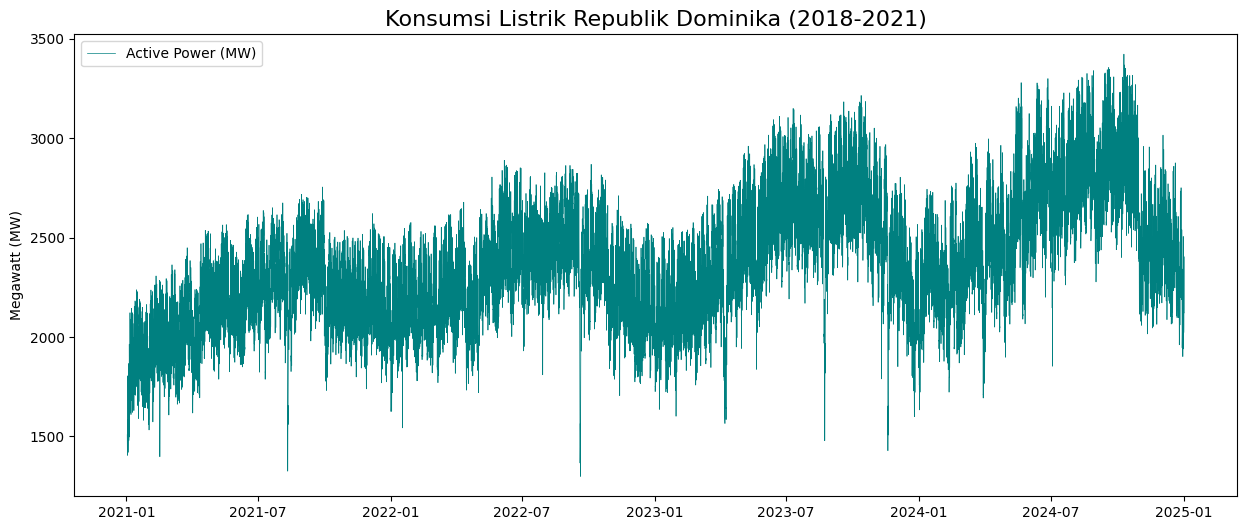

In [ ]:
plt.figure(figsize=(15, 6))
plt.plot(df.index, df['active_power_mw'], label='Active Power (MW)', linewidth=0.5, color='teal')
plt.title('Konsumsi Listrik Republik Dominika (2018-2021)', fontsize=16)
plt.ylabel('Megawatt (MW)')
plt.legend()
plt.ylim(min_power - 100, max_power + 100)
plt.show()

##Gambaran kebutuhan listrik dalam satu minggu

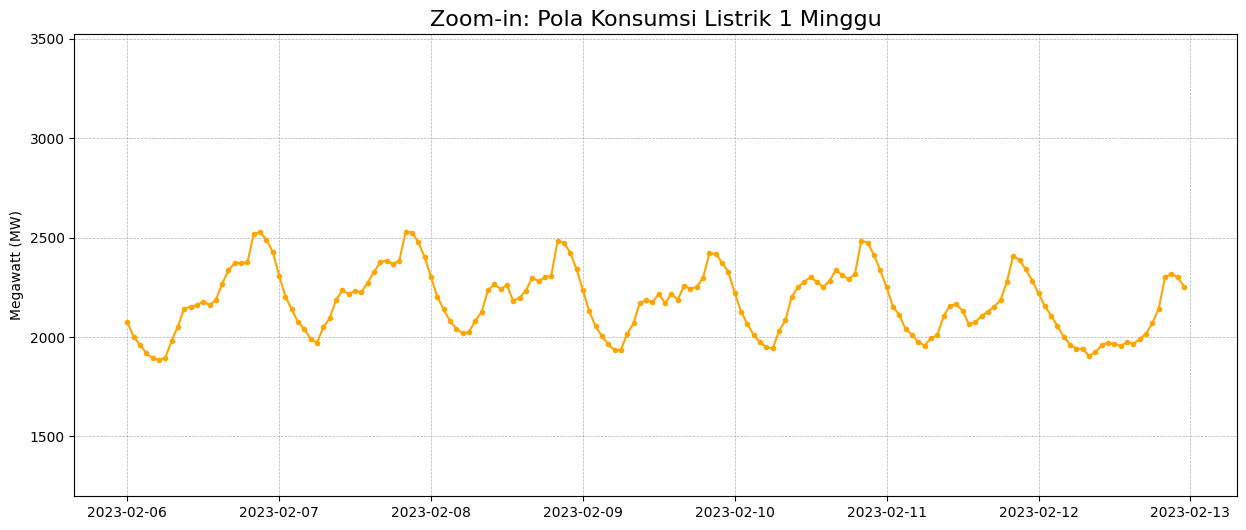

In [ ]:
subset = df.loc['2023-02-06':'2023-02-12']

plt.figure(figsize=(15, 6))
plt.plot(subset.index, subset['active_power_mw'], marker='.', linestyle='-', color='orange')
plt.title('Zoom-in: Pola Konsumsi Listrik 1 Minggu', fontsize=16)
plt.ylabel('Megawatt (MW)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.ylim(min_power - 100, max_power + 100) # Set consistent y-axis limits
plt.show()

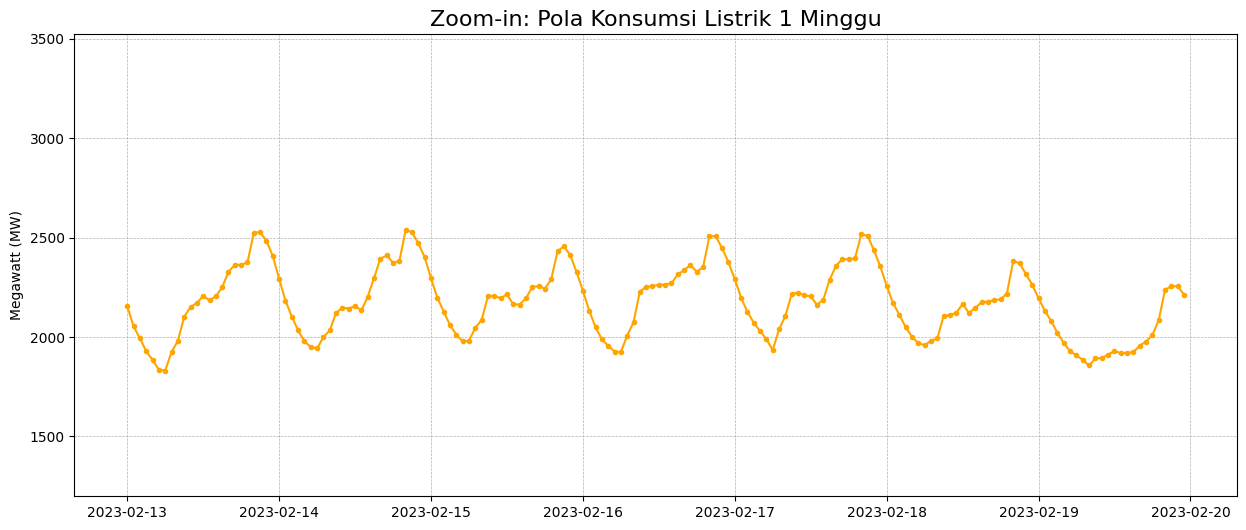

In [ ]:
subset = df.loc['2023-02-13':'2023-02-19']

plt.figure(figsize=(15, 6))
plt.plot(subset.index, subset['active_power_mw'], marker='.', linestyle='-', color='orange')
plt.title('Zoom-in: Pola Konsumsi Listrik 1 Minggu', fontsize=16)
plt.ylabel('Megawatt (MW)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.ylim(min_power - 100, max_power + 100) # Set consistent y-axis limits
plt.show()

##konsumsi listrik quartil pertama tiap tahun

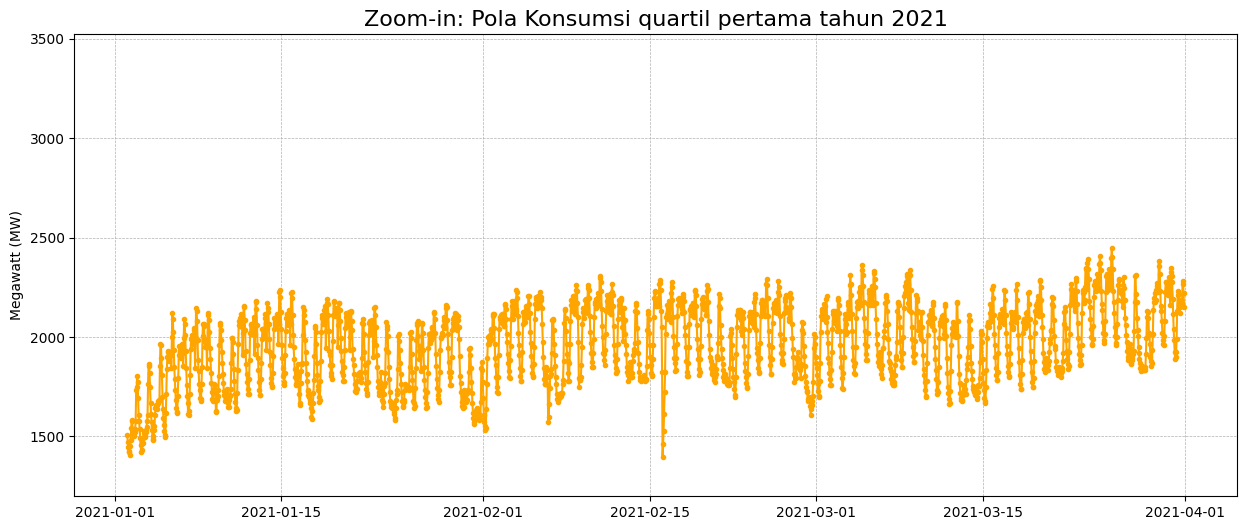

In [ ]:
subset = df.loc['2021-01-1':'2021-3-31']

plt.figure(figsize=(15, 6))
plt.plot(subset.index, subset['active_power_mw'], marker='.', linestyle='-', color='orange')
plt.title('Zoom-in: Pola Konsumsi quartil pertama tahun 2021', fontsize=16)
plt.ylabel('Megawatt (MW)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.ylim(min_power - 100, max_power + 100)
plt.show()

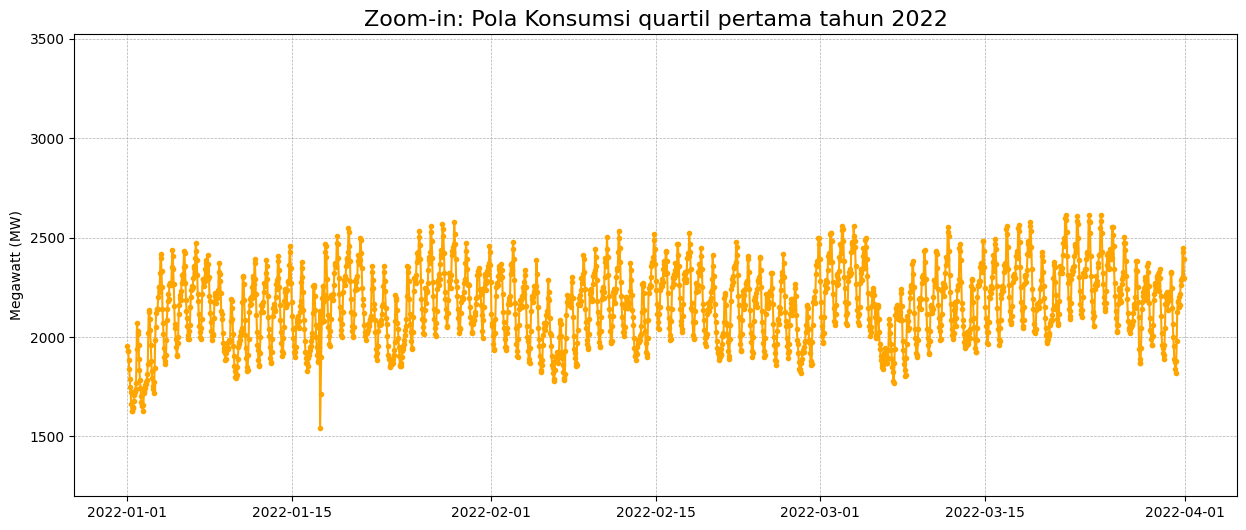

In [ ]:
subset = df.loc['2022-01-1':'2022-3-31']

plt.figure(figsize=(15, 6))
plt.plot(subset.index, subset['active_power_mw'], marker='.', linestyle='-', color='orange')
plt.title('Zoom-in: Pola Konsumsi quartil pertama tahun 2022', fontsize=16)
plt.ylabel('Megawatt (MW)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.ylim(min_power - 100, max_power + 100)
plt.show()

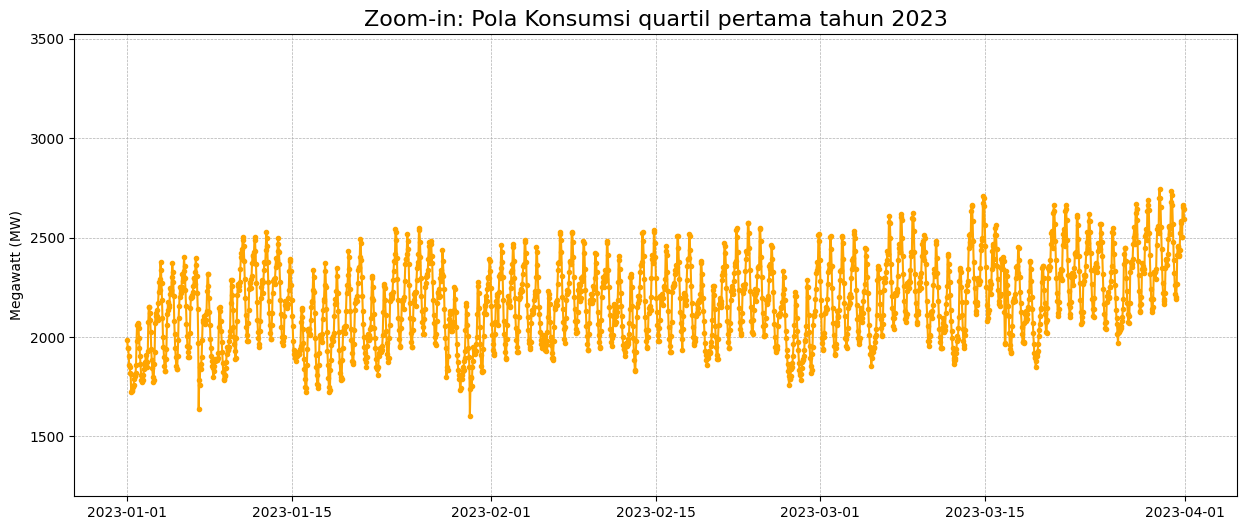

In [ ]:
subset = df.loc['2023-01-1':'2023-3-31']

plt.figure(figsize=(15, 6))
plt.plot(subset.index, subset['active_power_mw'], marker='.', linestyle='-', color='orange')
plt.title('Zoom-in: Pola Konsumsi quartil pertama tahun 2023', fontsize=16)
plt.ylabel('Megawatt (MW)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.ylim(min_power - 100, max_power + 100)
plt.show()

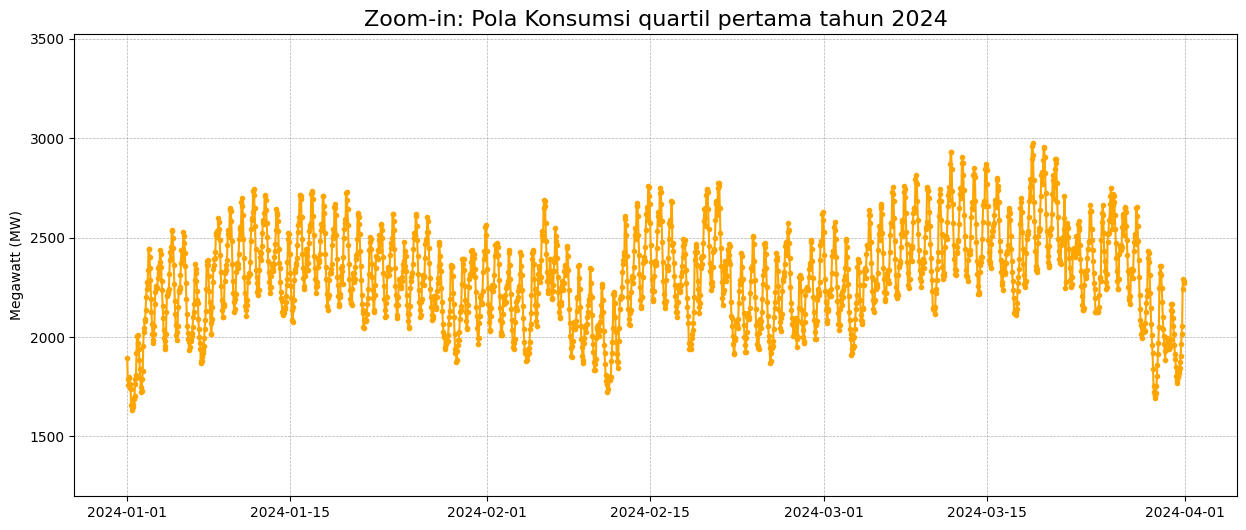

In [ ]:
subset = df.loc['2024-01-1':'2024-3-31']

plt.figure(figsize=(15, 6))
plt.plot(subset.index, subset['active_power_mw'], marker='.', linestyle='-', color='orange')
plt.title('Zoom-in: Pola Konsumsi quartil pertama tahun 2024', fontsize=16)
plt.ylabel('Megawatt (MW)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.ylim(min_power - 100, max_power + 100)
plt.show()

##konsumsi listrik harian

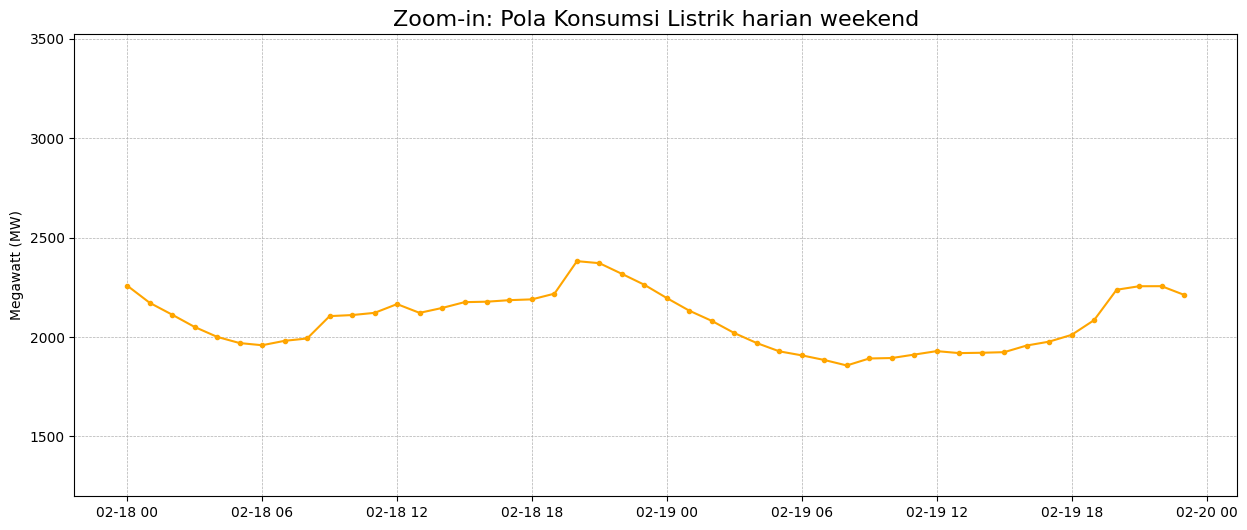

In [ ]:
subset = df.loc['2023-02-18':'2023-02-19']

plt.figure(figsize=(15, 6))
plt.plot(subset.index, subset['active_power_mw'], marker='.', linestyle='-', color='orange')
plt.title('Zoom-in: Pola Konsumsi Listrik harian weekend', fontsize=16)
plt.ylabel('Megawatt (MW)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.ylim(min_power - 100, max_power + 100)
plt.show()

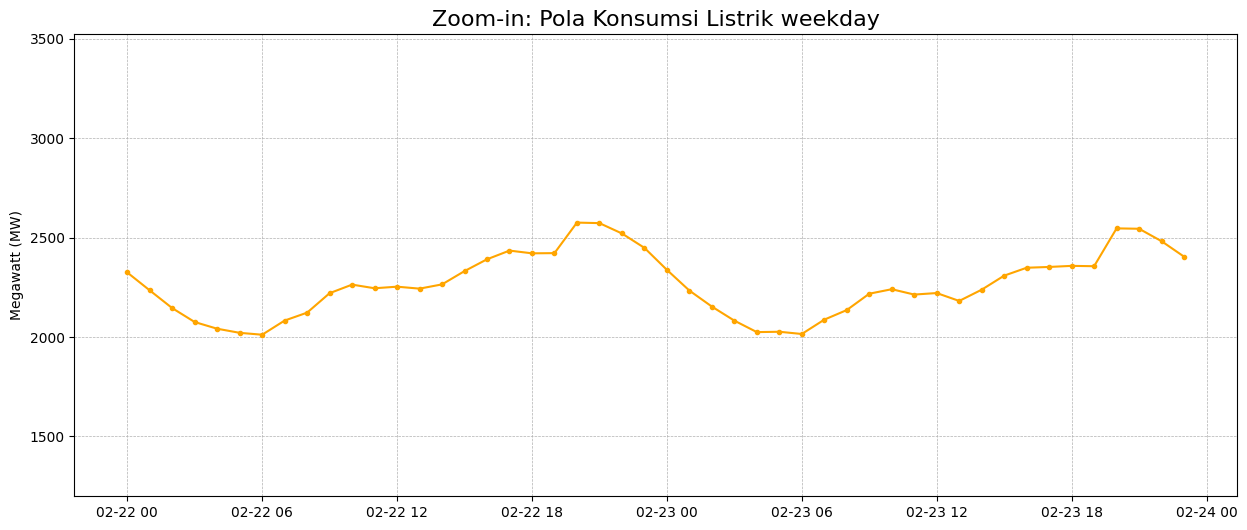

In [ ]:
subset = df.loc['2023-02-22':'2023-02-23']

plt.figure(figsize=(15, 6))
plt.plot(subset.index, subset['active_power_mw'], marker='.', linestyle='-', color='orange')
plt.title('Zoom-in: Pola Konsumsi Listrik weekday', fontsize=16)
plt.ylabel('Megawatt (MW)')
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.ylim(min_power - 100, max_power + 100)
plt.show()

##Cek outlier pada permintaan listrik

In [ ]:
df_processed = df.copy()

Q1 = df_processed['active_power_mw'].quantile(0.25)
Q3 = df_processed['active_power_mw'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df_processed[(df_processed['active_power_mw'] < lower_bound) |
                        (df_processed['active_power_mw'] > upper_bound)]

print(f"Jumlah outliers terdeteksi: {len(outliers)} ({len(outliers)/len(df_processed)*100:.2f}%)")
print(f"Lower bound: {lower_bound:.2f} MW")
print(f"Upper bound: {upper_bound:.2f} MW")

Jumlah outliers terdeteksi: 181 (0.52%)
Lower bound: 1495.31 MW
Upper bound: 3238.25 MW


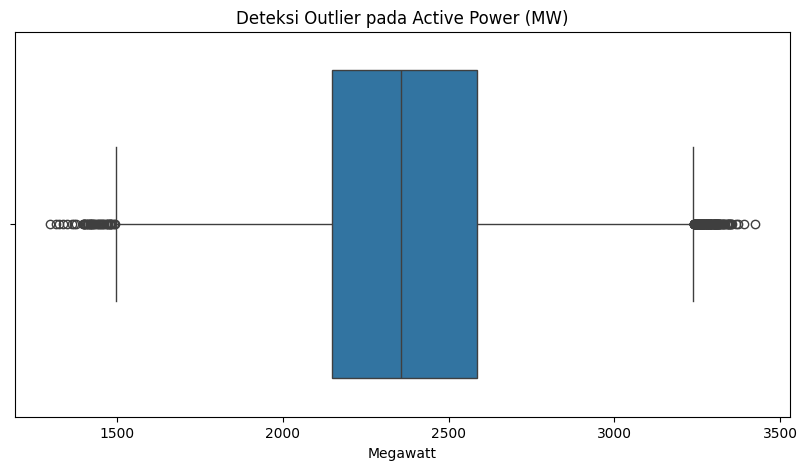

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(x=df['active_power_mw'])
plt.title('Deteksi Outlier pada Active Power (MW)')
plt.xlabel('Megawatt')
plt.show()

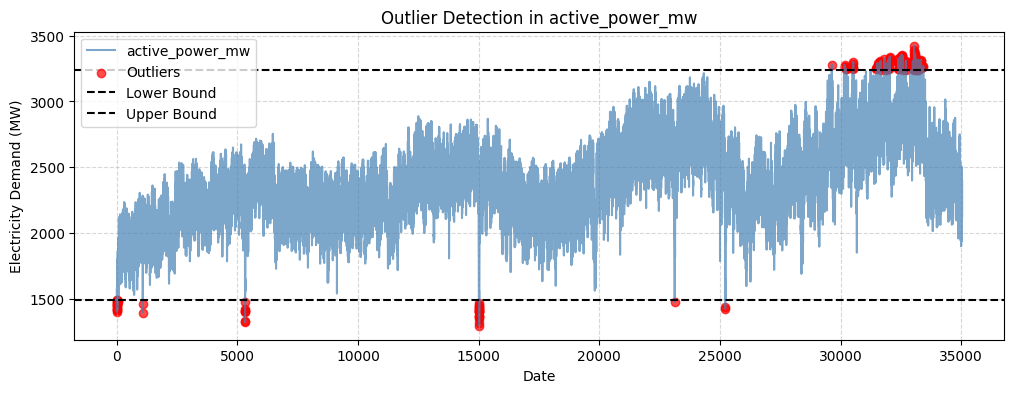

Total outliers detected: 181


In [ ]:
# Plot time series with outliers highlighted
plt.figure(figsize=(12, 4))
plt.plot(df_processed.index, df_processed["active_power_mw"], label="active_power_mw", color="steelblue", alpha=0.7)
plt.scatter(outliers.index, outliers["active_power_mw"], color="red", label="Outliers", alpha=0.7)
plt.axhline(lower_bound, color="black", linestyle="--", label="Lower Bound")
plt.axhline(upper_bound, color="black", linestyle="--", label="Upper Bound")
plt.title("Outlier Detection in active_power_mw")
plt.xlabel("Date")
plt.ylabel("Electricity Demand (MW)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.savefig('outlier_detection_electricity_demand.png', dpi=1000, bbox_inches="tight")
plt.show()

# Number of detected outliers
print(f"Total outliers detected: {outliers.shape[0]}")

##mengubah timestamp yang masih string

In [ ]:
df['timestamp'] = pd.to_datetime(df['timestamp'], format='%d/%m/%y %H:%M')
print("Berhasil konversi dengan format DD/MM/YY (Hari duluan)")

df = df.set_index('timestamp')
df = df.sort_index()

df = df.asfreq('H')

print(f"\nJumlah Baris Total: {len(df)}")
print(f"Jumlah NaN di active_power_mw: {df['active_power_mw'].isnull().sum()}")

print("\nCek Data 1 Februari 2021:")
print(df.loc['2021-02-01'].head(5))

Berhasil konversi dengan format DD/MM/YY (Hari duluan)

Jumlah Baris Total: 35039
Jumlah NaN di active_power_mw: 0

Cek Data 1 Februari 2021:
                     active_power_mw  apparent_temperature_c  \
timestamp                                                      
2021-02-01 00:00:00      1694.274680               23.843333   
2021-02-01 01:00:00      1609.835614               23.750000   
2021-02-01 02:00:00      1573.236899               23.686667   
2021-02-01 03:00:00      1549.822545               23.583333   
2021-02-01 04:00:00      1532.291319               23.446667   

                     cloud_cover_percent  month  hour  is_holiday  is_weekend  \
timestamp                                                                       
2021-02-01 00:00:00            44.800000      2     0           0           0   
2021-02-01 01:00:00            46.000000      2     1           0           0   
2021-02-01 02:00:00            47.166667      2     2           0           0   
2021

/tmp/ipython-input-1030523517.py:7: FutureWarning: 'H' is deprecated and will be removed in a future version, please use 'h' instead.
  df = df.asfreq('H')


##Cek duplikasi

In [ ]:
# Cek apakah ada duplikat di index
print(f"Jumlah Duplikat Timestamp: {df.index.duplicated().sum()}")

Jumlah Duplikat Timestamp: 0


##Mengecek nilai null

In [ ]:
df.isnull().sum()

,0
active_power_mw,0
apparent_temperature_c,0
cloud_cover_percent,0
month,0
hour,0
is_holiday,0
is_weekend,0
is_school_vacation,0
active_power_lag_1h,0
active_power_lag_2h,0


In [ ]:
print(f"Jumlah baris sebelum cleaning final: {len(df)}")

# Hapus semua baris yang punya setidaknya satu nilai NaN (akibat Lag)
df.dropna(inplace=True)

print(f"Jumlah baris setelah cleaning final: {len(df)}")

# Cek ulang apakah sudah bersih total
print(f"Total Null tersisa: {df.isna().sum().sum()}")

Jumlah baris sebelum cleaning final: 35039
Jumlah baris setelah cleaning final: 35039
Total Null tersisa: 0


##Ubah data menjadi data harian

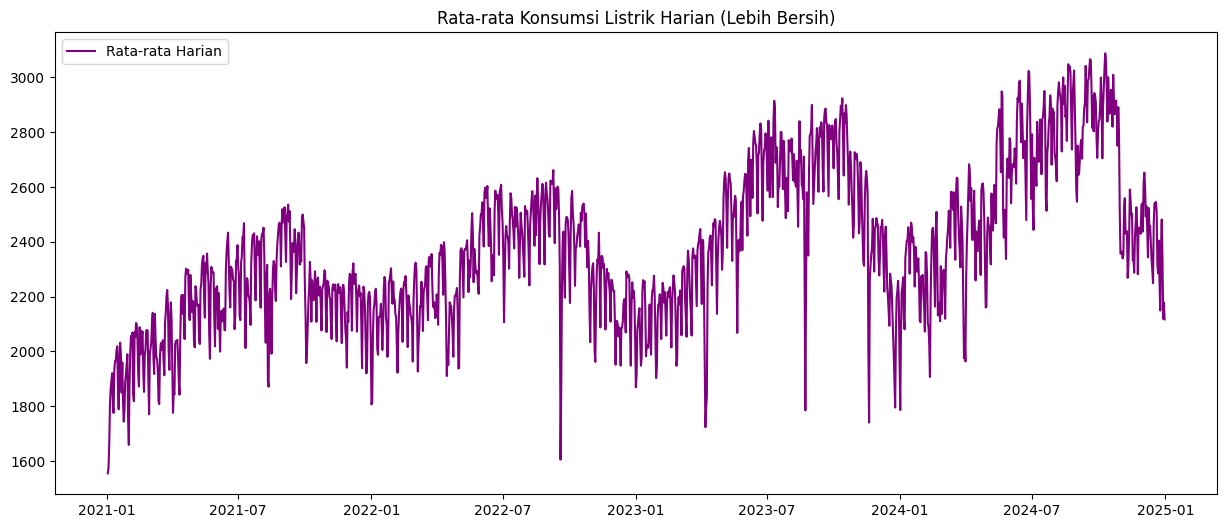

In [ ]:
# --- 2. RESAMPLING KE HARIAN (Daily Mean) ---
# Data per jam terlalu berisik (noisy) untuk melihat trend jangka panjang.
# Kita ambil rata-rata per hari.
df_daily = df['active_power_mw'].resample('D').mean()

# Plot Data Harian
plt.figure(figsize=(15, 6))
plt.plot(df_daily.index, df_daily, color='purple', label='Rata-rata Harian')
plt.title('Rata-rata Konsumsi Listrik Harian (Lebih Bersih)')
plt.legend()
plt.show()

##Cek apakah data stasioner

In [ ]:
def cek_stasioneritas_simple(timeseries):
    print(f"Hasil Uji Dickey-Fuller:")
    dftest = adfuller(timeseries.dropna(), autolag='AIC')
    output = pd.Series(dftest[0:4], index=['Test Statistic','p-value','#Lags Used','Number of Observations Used'])
    print(output)

    if output['p-value'] < 0.05:
        print("\n Kesimpulan: Data STASIONER (Siap dimodelkan)")
    else:
        print("\n Kesimpulan: Data TIDAK STASIONER (Ada Trend/Musiman)")

print("\n--- Cek Stasioneritas Data Harian ---")
cek_stasioneritas_simple(df_daily)


--- Cek Stasioneritas Data Harian ---
Hasil Uji Dickey-Fuller:
Test Statistic                   -2.609277
p-value                           0.091095
#Lags Used                       24.000000
Number of Observations Used    1435.000000
dtype: float64

 Kesimpulan: Data TIDAK STASIONER (Ada Trend/Musiman)


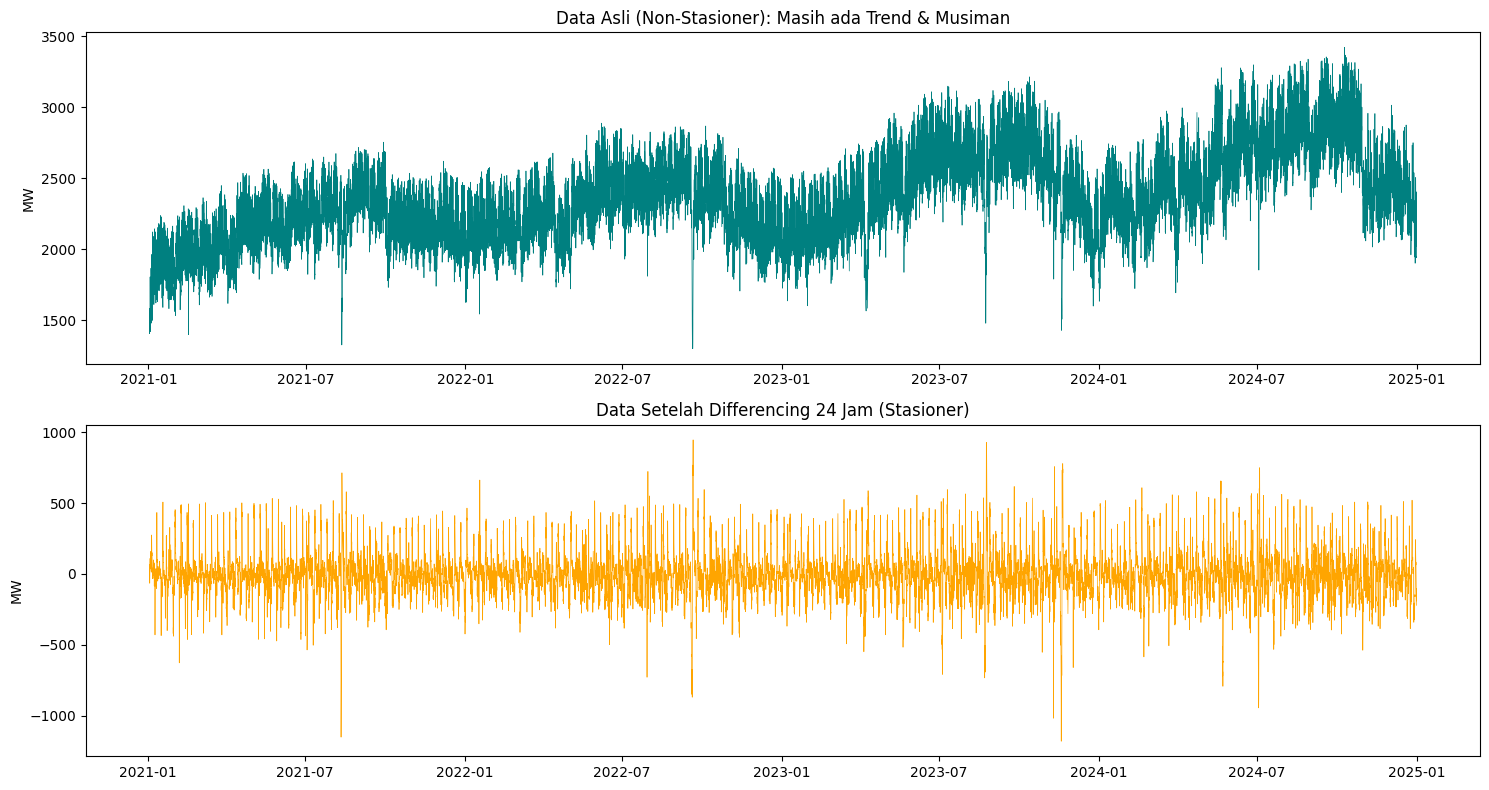

In [ ]:
df['active_power_diff'] =  df['active_power_mw'].diff(24)

plt.figure(figsize=(15, 8))

plt.subplot(2, 1, 1)
plt.plot(df.index, df['active_power_mw'], color='teal', linewidth=0.5)
plt.title('Data Asli (Non-Stasioner): Masih ada Trend & Musiman')
plt.ylabel('MW')

plt.subplot(2, 1, 2)
plt.plot(df.index, df['active_power_diff'], color='orange', linewidth=0.5)
plt.title('Data Setelah Differencing 24 Jam (Stasioner)')
plt.ylabel('MW')

plt.tight_layout()
plt.show()

In [ ]:
print("\n--- Cek Stasioneritas Data Diff ---")
df_diff_daily = df['active_power_diff'].resample('D').mean().dropna()

result =  adfuller(df_diff_daily)
print(f"p-value: {result[1]}")

if result[1] < 0.05:
    print("SUKSES! Data menjadi Stasioner.")
else:
    print("Masih belum stasioner.")


--- Cek Stasioneritas Data Diff ---
p-value: 2.1542396471979734e-19
SUKSES! Data menjadi Stasioner.


In [ ]:
df.isnull().sum()

,0
active_power_mw,0
apparent_temperature_c,0
cloud_cover_percent,0
month,0
hour,0
is_holiday,0
is_weekend,0
is_school_vacation,0
active_power_lag_1h,0
active_power_lag_2h,0


In [ ]:
#hapus 24 baris pertama dari kolom active_power_diff
df.dropna(inplace=True)

In [ ]:
df.isnull().sum()

,0
active_power_mw,0
apparent_temperature_c,0
cloud_cover_percent,0
month,0
hour,0
is_holiday,0
is_weekend,0
is_school_vacation,0
active_power_lag_1h,0
active_power_lag_2h,0


#Modeling

##Splitting

In [ ]:
train_size = int(len(df) * 0.70)
val_size = int(len(df) * 0.15)

train_data = df.iloc[:train_size]
val_data = df.iloc[train_size:train_size + val_size]
test_data = df.iloc[train_size + val_size:]

print(f"Jumlah Data Training  : {len(train_data)} jam")
print(f"Jumlah Data Validation: {len(val_data)} jam")
print(f"Jumlah Data Testing   : {len(test_data)} jam")
print(f"Training dari  : {train_data.index.min()} sampai {train_data.index.max()}")
print(f"Validation dari: {val_data.index.min()} sampai {val_data.index.max()}")
print(f"Testing dari   : {test_data.index.min()} sampai {test_data.index.max()}")

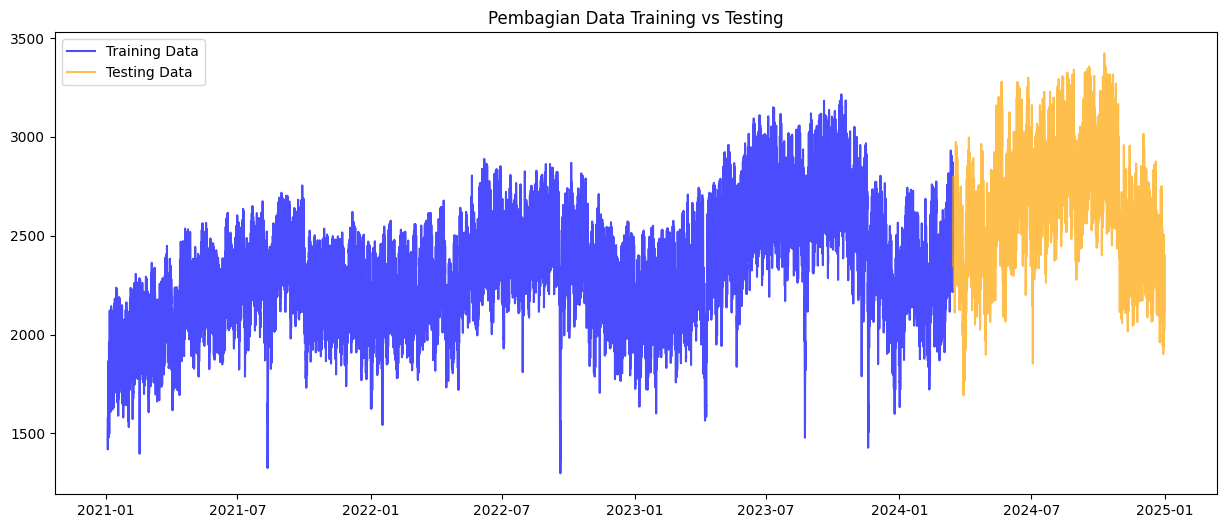

In [ ]:
# Visualisasi Pembagian
plt.figure(figsize=(15, 6))
plt.plot(train_data.index, train_data['active_power_mw'], label='Training Data', color='blue', alpha=0.7)
plt.plot(test_data.index, test_data['active_power_mw'], label='Testing Data', color='orange', alpha=0.7)
plt.title('Pembagian Data Training vs Testing')
plt.legend()
plt.show()

##Machine Learning Model

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error, mean_absolute_error # <--- Tambah ini
import numpy as np
import xgboost as xgb

def evaluasi_model(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = mean_absolute_percentage_error(y_true, y_pred) * 100
    mae = mean_absolute_error(y_true, y_pred)

    print(f"--- Evaluasi: {model_name} ---")
    print(f"RMSE : {rmse:.2f} MW")
    print(f"MAE  : {mae:.2f} MW")
    print(f"MAPE : {mape:.2f} %")
    print("-" * 30)

    return rmse, mape, mae

In [ ]:
# Skenario 1: Naive Persistence (Prediksi = Nilai 24 jam yang lalu)
y_test_baseline = test_data['active_power_lag_24h']
y_test_aktual = test_data['active_power_mw']

# Evaluasi
rmse_base, mape_base, mae_base = evaluasi_model(y_test_aktual, y_test_baseline, "Baseline (Naive 24h)")

--- Evaluasi: Baseline (Naive 24h) ---
RMSE : 174.29 MW
MAE  : 127.19 MW
MAPE : 4.90 %
------------------------------


In [ ]:
# 2. XGBOOST & LINREG (Feature Based)
target = 'active_power_mw'

# DAFTAR BLACKLIST (Kolom yang tidak boleh jadi fitur)
# 1. Target itu sendiri
# 2. Turunan langsung target yang membocorkan masa depan (seperti diff)
cols_to_drop = [target, 'active_power_diff']

# Pilih kolom selain yang di-blacklist
fitur_cols = [col for col in df.columns if col not in cols_to_drop]

print(f"Fitur yang digunakan ({len(fitur_cols)}):")
print(fitur_cols)
# Pastikan tidak ada 'active_power_diff' di sini!

X_train = train_data[fitur_cols]
y_train = train_data[target]
X_val = val_data[fitur_cols]
y_val = val_data[target]
X_test = test_data[fitur_cols]
y_test = test_data[target]

In [ ]:
print("\n2. XGBOOST")
reg = xgb.XGBRegressor(n_estimators=1000, learning_rate=0.05, early_stopping_rounds=50, n_jobs=-1)
reg.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=0)

y_pred_xgb = reg.predict(X_test)
rmse_xgb, mape_xgb, mae_xgb = evaluasi_model(y_test, y_pred_xgb, "XGBoost Regressor")

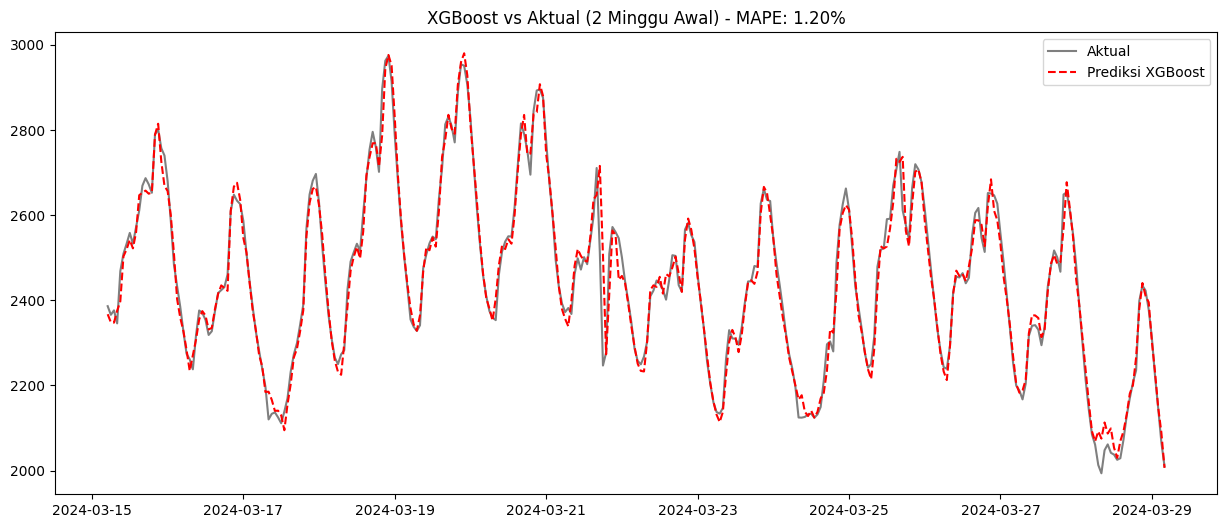

In [ ]:
# Plot XGBoost
plt.figure(figsize=(15, 6))
df_hasil_xgb = pd.DataFrame({'Aktual': y_test, 'Prediksi': y_pred_xgb}, index=y_test.index)
subset_xgb = df_hasil_xgb.iloc[:24*14]
plt.plot(subset_xgb.index, subset_xgb['Aktual'], label='Aktual', color='black', alpha=0.5)
plt.plot(subset_xgb.index, subset_xgb['Prediksi'], label='Prediksi XGBoost', color='red', linestyle='--')
plt.title(f'XGBoost vs Aktual (2 Minggu Awal) - MAPE: {mape_xgb:.2f}%')
plt.legend()
plt.show()

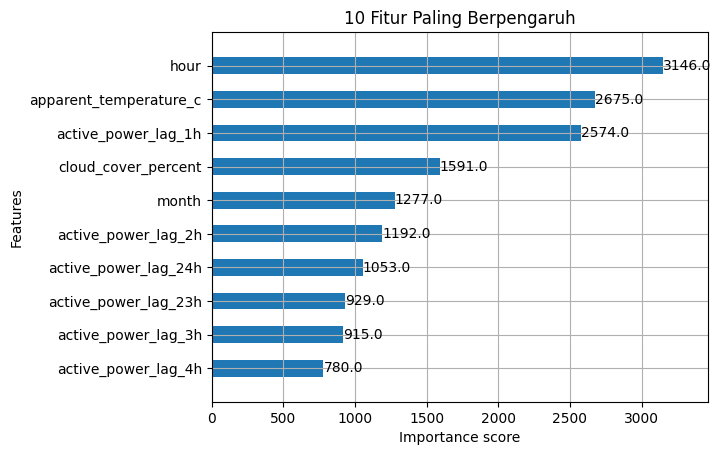

In [ ]:
# Cek Feature Importance (Apa yang paling mempengaruhi listrik?)
xgb.plot_importance(reg, max_num_features=10, height=0.5)
plt.title("10 Fitur Paling Berpengaruh")
plt.show()

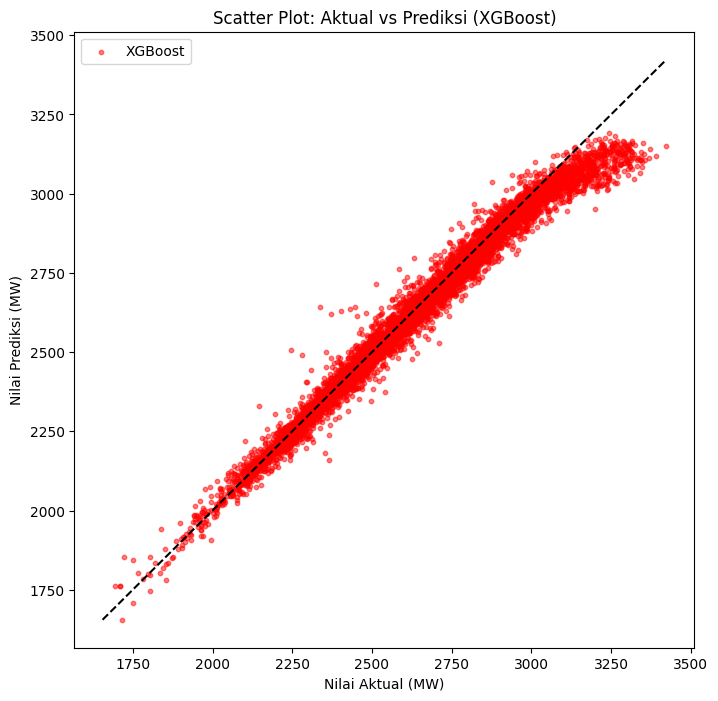

In [ ]:
plt.figure(figsize=(8, 8))

# Plot XGBoost
plt.scatter(y_test_aktual, y_pred_xgb, alpha=0.5, color='red', s=10, label='XGBoost')

# Garis Diagonal Sempurna (x=y)
min_val = min(y_test_aktual.min(), y_pred_xgb.min())
max_val = max(y_test_aktual.max(), y_pred_xgb.max())
plt.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--')

plt.title('Scatter Plot: Aktual vs Prediksi (XGBoost)')
plt.xlabel('Nilai Aktual (MW)')
plt.ylabel('Nilai Prediksi (MW)')
plt.legend()
plt.show()

##Linear Regression

In [ ]:
model_lr = LinearRegression()
model_lr.fit(X_train, y_train)

y_pred_lr = model_lr.predict(X_test)
rmse_lr, mape_lr, mae_lr = evaluasi_model(y_test, y_pred_lr, "Linear Regression")

--- Evaluasi: Linear Regression ---
RMSE : 45.89 MW
MAE  : 34.02 MW
MAPE : 1.29 %
------------------------------


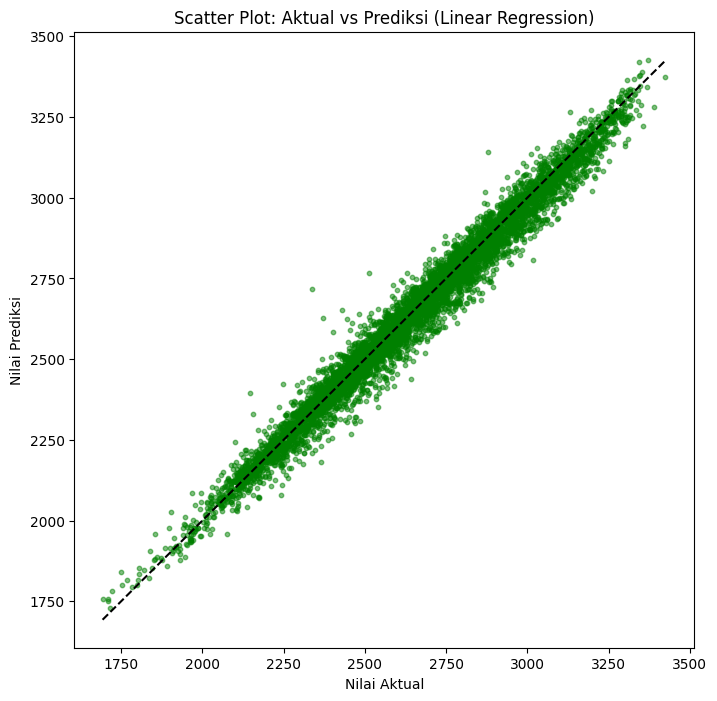

In [ ]:
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_lr, alpha=0.5, color='green', s=10)
min_val, max_val = min(y_test.min(), y_pred_lr.min()), max(y_test.max(), y_pred_lr.max())
plt.plot([min_val, max_val], [min_val, max_val], color='black', linestyle='--')
plt.title('Scatter Plot: Aktual vs Prediksi (Linear Regression)') # <--- Judul diperbaiki
plt.xlabel('Nilai Aktual')
plt.ylabel('Nilai Prediksi')
plt.show()

/tmp/ipython-input-1307919701.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x='Koefisien', y='Fitur', palette='viridis')


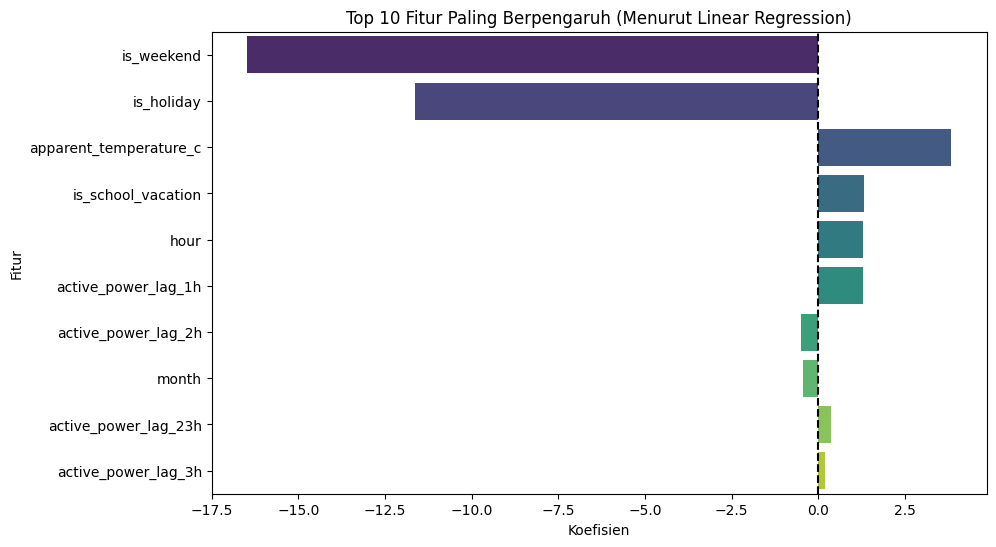

In [ ]:
# Ambil koefisien dan nama fiturnya
coef_df = pd.DataFrame({
    'Fitur': X_train.columns,
    'Koefisien': model_lr.coef_
})

# Urutkan berdasarkan nilai absolut (biar yang pengaruhnya besar ada di atas)
coef_df['Abs_Koefisien'] = coef_df['Koefisien'].abs()
coef_df = coef_df.sort_values(by='Abs_Koefisien', ascending=False).head(10) # Top 10

# Visualisasi
plt.figure(figsize=(10, 6))
sns.barplot(data=coef_df, x='Koefisien', y='Fitur', palette='viridis')
plt.title('Top 10 Fitur Paling Berpengaruh (Menurut Linear Regression)')
plt.axvline(0, color='black', linestyle='--')
plt.show()

##LSTM with Sliding Window

In [ ]:
# 1. Ambil Data Mentah Saja
# Kita buang semua kolom 'lag_' buatan dataset karena kita mau buat sendiri via sliding window
cols_to_use = ['active_power_mw', 'apparent_temperature_c', 'cloud_cover_percent', 'is_holiday', 'is_weekend', 'hour', 'month']
data_raw = df[cols_to_use].copy()

print(f"Fitur yang dipakai ({len(cols_to_use)}): {cols_to_use}")

# 2. Split Train/Val/Test (Index based, 70/15/15)
train_size = int(len(data_raw) * 0.70)
val_size = int(len(data_raw) * 0.15)

train_df = data_raw.iloc[:train_size]
val_df = data_raw.iloc[train_size:train_size + val_size]
test_df = data_raw.iloc[train_size + val_size:]

# 3. Scaling (Wajib 0-1)
# Kita pakai 2 Scaler: Satu untuk SEMUA fitur (biar masuk ke X), Satu khusus TARGET (biar gampang inverse nanti)
scaler_all = MinMaxScaler(feature_range=(0, 1))
scaler_target = MinMaxScaler(feature_range=(0, 1))

# Fit di Train saja, transform semua split
scaled_train = scaler_all.fit_transform(train_df)
scaled_val = scaler_all.transform(val_df)
scaled_test = scaler_all.transform(test_df)

# Fit Target Scaler (Hanya kolom active_power_mw, kolom ke-0)
scaler_target.fit(train_df[['active_power_mw']])

In [ ]:
def create_sequences(data, time_steps=24):
    """
    Mengubah data 2D menjadi 3D untuk LSTM.
    X = Urutan data sepanjang 'time_steps' (misal 24 jam ke belakang)
    y = Nilai target di 1 jam ke depan
    """
    Xs, ys = [], []
    # Loop dari jam ke-24 sampai akhir
    for i in range(len(data) - time_steps):
        # Ambil baris i sampai i+24 sebagai Input (X)
        Xs.append(data[i:(i + time_steps)])

        # Ambil baris i+24 kolom ke-0 (active_power) sebagai Target (y)
        ys.append(data[i + time_steps, 0])

    return np.array(Xs), np.array(ys)

# Tentukan Window Size (Sequence Length)
TIME_STEPS = 24

# Buat Sequence untuk Train, Validation, dan Test
X_train_seq, y_train_seq = create_sequences(scaled_train, TIME_STEPS)
X_val_seq, y_val_seq = create_sequences(scaled_val, TIME_STEPS)
X_test_seq, y_test_seq = create_sequences(scaled_test, TIME_STEPS)

print(f"Dimensi X_train: {X_train_seq.shape} -> (Samples, Time Steps, Features)")
print(f"Dimensi X_val  : {X_val_seq.shape}")
print(f"Dimensi X_test : {X_test_seq.shape}")
print(f"Dimensi y_train: {y_train_seq.shape}")

In [ ]:
model_seq = Sequential()

# Layer 1: LSTM
model_seq.add(Input(shape=(X_train_seq.shape[1], X_train_seq.shape[2])))
model_seq.add(LSTM(units=64, return_sequences=True)) # True biar nyambung ke LSTM berikutnya
model_seq.add(Dropout(0.2))

# Layer 2: LSTM
model_seq.add(LSTM(units=32, return_sequences=False)) # False karena ini layer LSTM terakhir
model_seq.add(Dropout(0.2))

# Output Layer
model_seq.add(Dense(1)) # Prediksi 1 angka (MW)

model_seq.compile(optimizer='adam', loss='mean_squared_error')
model_seq.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_9 (LSTM)                   │ (None, 24, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_10 (LSTM)                  │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,881 (120.63 KB)

 Trainable params: 30,881 (120.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

history_seq = model_seq.fit(
    X_train_seq, y_train_seq,
    epochs=20,
    batch_size=64,
    validation_data=(X_val_seq, y_val_seq),
    callbacks=[early_stop],
    verbose=1
)

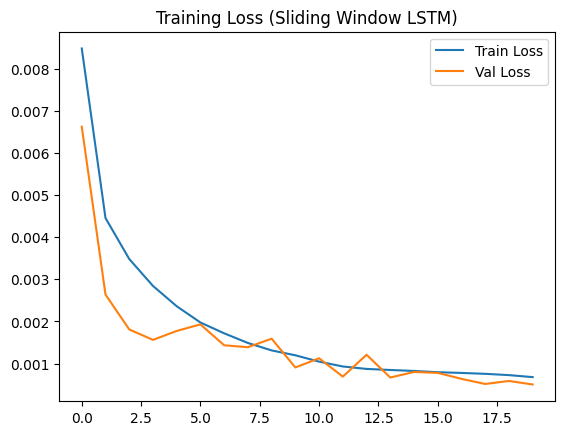

In [ ]:
plt.plot(history_seq.history['loss'], label='Train Loss')
plt.plot(history_seq.history['val_loss'], label='Val Loss')
plt.title('Training Loss (Sliding Window LSTM)')
plt.legend()
plt.show()

In [ ]:
# Prediksi & Evaluasi
y_pred_lstm_scaled = model_seq.predict(X_test_seq)
y_pred_lstm_inv = scaler_target.inverse_transform(y_pred_lstm_scaled)
y_test_lstm_inv = scaler_target.inverse_transform(y_test_seq.reshape(-1, 1))

219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [ ]:
rmse_lstm = np.sqrt(mean_squared_error(y_test_lstm_inv, y_pred_lstm_inv))
mae_lstm = mean_absolute_error(y_test_lstm_inv, y_pred_lstm_inv)
mape_lstm = mean_absolute_percentage_error(y_test_lstm_inv, y_pred_lstm_inv) * 100

print(f"--- Evaluasi: LSTM Sliding Window ---")
print(f"RMSE : {rmse_lstm:.2f} MW")
print(f"MAE  : {mae_lstm:.2f} MW")
print(f"MAPE : {mape_lstm:.2f} %")

--- Evaluasi: LSTM Sliding Window ---
RMSE : 42.92 MW
MAE  : 31.77 MW
MAPE : 1.21 %


In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_percentage_error
import math

# 1. Prediksi
y_pred_scaled = model_seq.predict(X_test_seq)

# 2. Inverse Transform (Kembalikan ke MW asli)
y_pred_inv = scaler_target.inverse_transform(y_pred_scaled)
y_test_inv = scaler_target.inverse_transform(y_test_seq.reshape(-1, 1))

# 3. Hitung Error
mape_lstm_seq = mean_absolute_percentage_error(y_test_inv, y_pred_inv) * 100

print(f"HASIL AKHIR")
print(f"XGBoost MAPE      : {mape_xgb:.2f}%")
print(f"Linreg MAPE      : {mape_lr:.2f}%")
print(f"LSTM (Sliding): {mape_lstm_seq:.2f} %")
print("-" * 40)

219/219 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
HASIL AKHIR
XGBoost MAPE      : 1.20%
Linreg MAPE      : 1.29%
LSTM (Sliding): 0.97 %
----------------------------------------


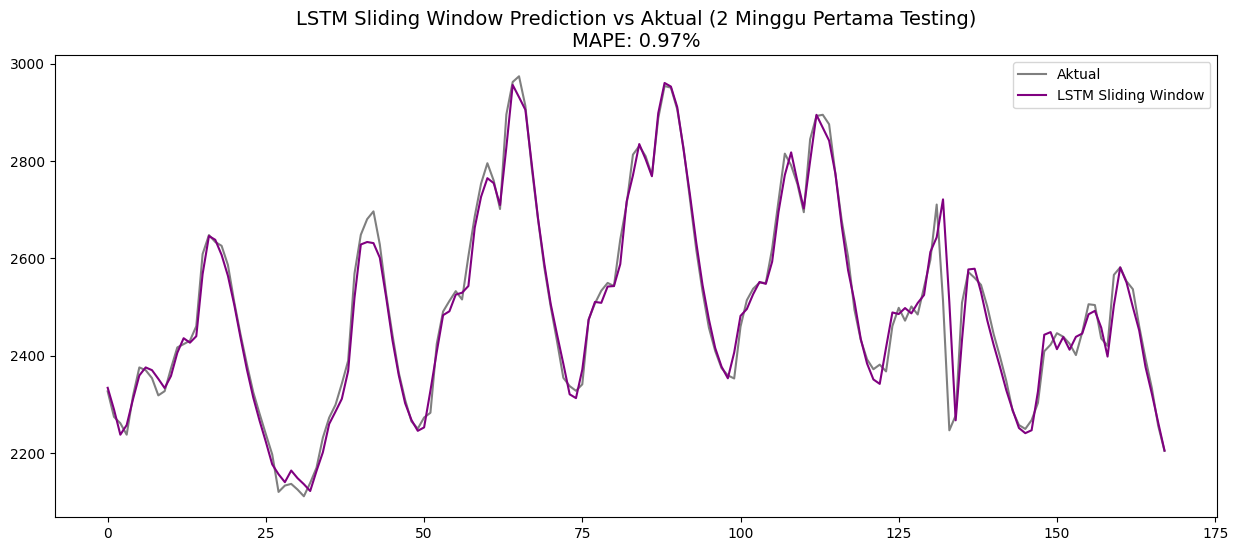

In [ ]:
# Visualisasi
limit = 24*7
plt.figure(figsize=(15, 6))
plt.plot(y_test_inv[:limit], label='Aktual', color='black', alpha=0.5)
plt.plot(y_pred_inv[:limit], label='LSTM Sliding Window', color='purple')
# plt.title('LSTM Sliding Window Prediction')
plt.title(f'LSTM Sliding Window Prediction vs Aktual (2 Minggu Pertama Testing)\nMAPE: {mape_lstm:.2f}%', fontsize=14)
plt.legend()
plt.show()

##Visualisasi Perbandingan Hasil

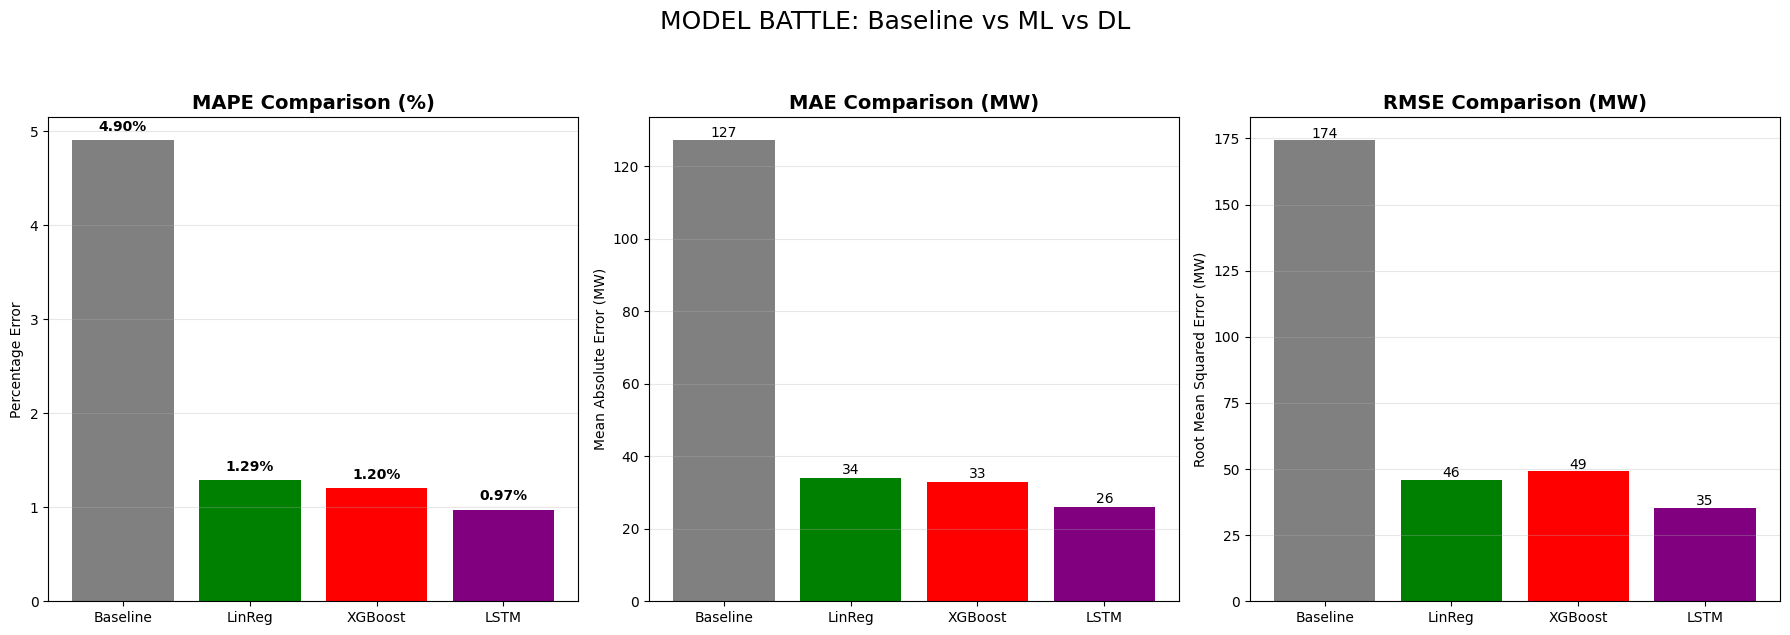

In [ ]:
models = ['Baseline', 'LinReg', 'XGBoost', 'LSTM']
mapes = [mape_base, mape_lr, mape_xgb, mape_lstm]
maes = [mae_base, mae_lr, mae_xgb, mae_lstm]
rmses = [rmse_base, rmse_lr, rmse_xgb, rmse_lstm]

# Setup Plot 3 Subplot
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
colors = ['gray', 'green', 'red', 'purple']

# Plot 1: MAPE
bars1 = axes[0].bar(models, mapes, color=colors)
axes[0].set_title('MAPE Comparison (%)', fontsize=14, fontweight='bold')
axes[0].set_ylabel('Percentage Error')
axes[0].grid(axis='y', alpha=0.3)
# Label Angka
for bar in bars1:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.1,
                 f'{bar.get_height():.2f}%', ha='center', fontweight='bold')

# Plot 2: MAE
bars2 = axes[1].bar(models, maes, color=colors)
axes[1].set_title('MAE Comparison (MW)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Mean Absolute Error (MW)')
axes[1].grid(axis='y', alpha=0.3)
for bar in bars2:
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{bar.get_height():.0f}', ha='center')

# Plot 3: RMSE
bars3 = axes[2].bar(models, rmses, color=colors)
axes[2].set_title('RMSE Comparison (MW)', fontsize=14, fontweight='bold')
axes[2].set_ylabel('Root Mean Squared Error (MW)')
axes[2].grid(axis='y', alpha=0.3)
for bar in bars3:
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{bar.get_height():.0f}', ha='center')

plt.suptitle('MODEL BATTLE: Baseline vs ML vs DL', fontsize=18, y=1.05)
plt.tight_layout()
plt.show()

##Simpan Model

In [ ]:
import joblib

# 1. Simpan Model LSTM
# Pastikan 'model_seq' adalah variabel model terbaikmu
model_seq.save('model_lstm_listrik.keras')

# 2. Simpan Scaler (SANGAT PENTING!)
# Tanpa ini, model bingung karena input user beda skala
joblib.dump(scaler_all, 'scaler_all.pkl')
joblib.dump(scaler_target, 'scaler_target.pkl')

print("Model dan Scaler berhasil disimpan!")

Model dan Scaler berhasil disimpan!


In [ ]:
# 1. Ambil 200 baris pertama dari data testing
# Kita ambil agak banyak karena LSTM butuh 24 baris sebelumnya sebagai "jendela ngintip"
df_sample = test_data.head(200).copy()

# 2. Reset Index
# (Agar 'timestamp' yang tadinya index berubah jadi kolom biasa lagi)
df_sample.reset_index(inplace=True)

# 3. Simpan ke CSV
df_sample.to_csv('sample_test_data.csv', index=False)

print("File 'sample_test_data.csv' berhasil dibuat!")
print("Silakan download file ini untuk di-upload ke Streamlit.")

File 'sample_test_data.csv' berhasil dibuat!
Silakan download file ini untuk di-upload ke Streamlit.


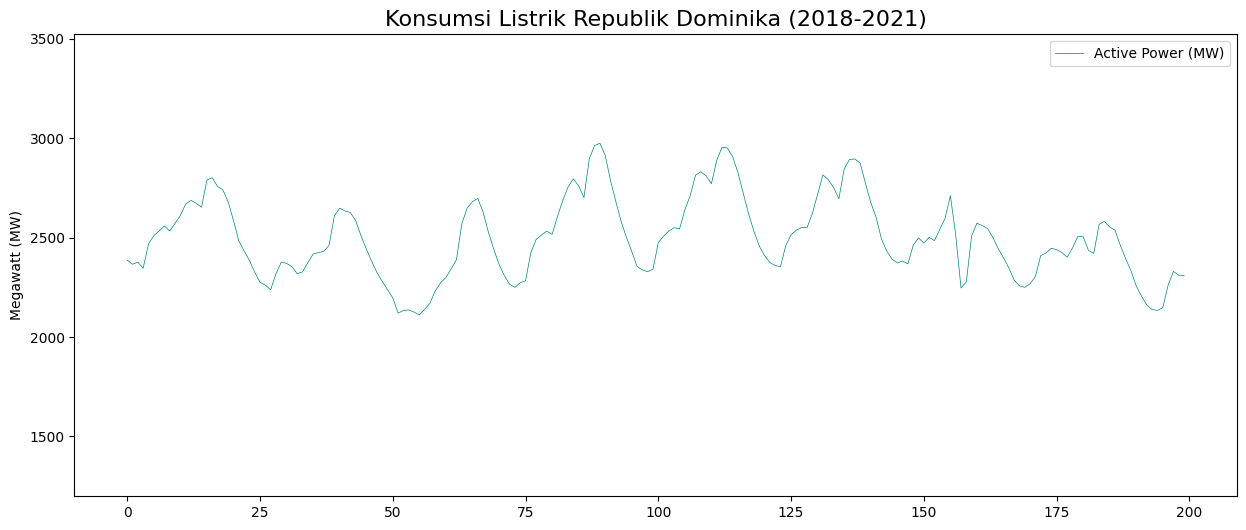

In [ ]:
plt.figure(figsize=(15, 6))
plt.plot(df_sample.index, df_sample['active_power_mw'], label='Active Power (MW)', linewidth=0.5, color='teal')
plt.title('Konsumsi Listrik Republik Dominika (2018-2021)', fontsize=16)
plt.ylabel('Megawatt (MW)')
plt.legend()
plt.ylim(min_power - 100, max_power + 100)
plt.show()

#Hyperparameter Tuning

In [ ]:
!pip install keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 9.0 MB/s eta 0:00:00


In [ ]:
import keras_tuner as kt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam

# 1. Definisikan Fungsi "Model Builder"
# Fungsi ini akan membuat model dengan parameter yang berubah-ubah (hp)
def build_model(hp):
    model = Sequential()

    # Input Layer
    model.add(Input(shape=(X_train_seq.shape[1], X_train_seq.shape[2])))

    # Layer 1: LSTM (Kita tune jumlah unitnya)
    # hp.Int akan memilih angka antara 32 sampai 128 dengan kelipatan 32
    hp_units1 = hp.Int('units_1', min_value=32, max_value=128, step=32)
    model.add(LSTM(units=hp_units1, return_sequences=True))

    # Dropout Layer 1 (Kita tune persentasenya)
    hp_dropout1 = hp.Float('dropout_1', min_value=0.1, max_value=0.5, step=0.1)
    model.add(Dropout(hp_dropout1))

    # Layer 2: LSTM
    hp_units2 = hp.Int('units_2', min_value=16, max_value=64, step=16)
    model.add(LSTM(units=hp_units2, return_sequences=False))

    # Dropout Layer 2
    hp_dropout2 = hp.Float('dropout_2', min_value=0.1, max_value=0.5, step=0.1)
    model.add(Dropout(hp_dropout2))

    # Output Layer
    model.add(Dense(1))

    # Tuning Learning Rate (Sangat Penting!)
    hp_lr = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])

    model.compile(optimizer=Adam(learning_rate=hp_lr),
                  loss='mean_squared_error')

    return model

In [ ]:
# 2. Setup Tuner
# Kita pakai 'Hyperband' (Algoritma pintar yang cepat membuang model jelek)
tuner = kt.Hyperband(
    build_model,
    objective='val_loss',
    max_epochs=20,
    factor=3,
    directory='my_dir',       # Folder penyimpanan log
    project_name='lstm_tuning'
)

In [ ]:
# 3. Hentikan jika tidak ada perbaikan (Biar hemat waktu)
stop_early = EarlyStopping(monitor='val_loss', patience=5)

print("Mulai Tuning LSTM... (Siapkan kopi, ini agak lama)")

# 4. Jalankan Pencarian
tuner.search(
    X_train_seq, y_train_seq,
    epochs=20,
    validation_data=(X_val_seq, y_val_seq),
    callbacks=[stop_early],
    verbose=1
)

# --- AMBIL HASIL TERBAIK ---
print("\n" + "="*40)
print("HASIL TUNING SELESAI")
print("="*40)

# Ambil hyperparameters terbaik
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print(f"Jumlah Unit LSTM 1 : {best_hps.get('units_1')}")
print(f"Dropout 1          : {best_hps.get('dropout_1')}")
print(f"Jumlah Unit LSTM 2 : {best_hps.get('units_2')}")
print(f"Learning Rate      : {best_hps.get('learning_rate')}")

In [ ]:
# --- RETRAIN MODEL TERBAIK ---
# Kita latih ulang model terbaik dengan epoch yang agak panjang
print("\nMelatih ulang model dengan parameter terbaik...")
best_model = tuner.hypermodel.build(best_hps)

history_best = best_model.fit(
    X_train_seq, y_train_seq,
    epochs=50, # Kasih waktu lebih lama
    validation_data=(X_val_seq, y_val_seq),
    callbacks=[stop_early],
    verbose=1
)

# --- EVALUASI FINAL ---
y_pred_tuned_scaled = best_model.predict(X_test_seq)
y_pred_tuned_inv = scaler_target.inverse_transform(y_pred_tuned_scaled)
y_test_inv = scaler_target.inverse_transform(y_test_seq.reshape(-1, 1))

mape_tuned = mean_absolute_percentage_error(y_test_inv, y_pred_tuned_inv) * 100

print(f"\nFINAL MAPE (LSTM Tuned): {mape_tuned:.2f}%")